# Synthetic banking data - exploratory analysis & feature contract draft (TASK-010)

**Data:** `pbip_datagen` v1, generated in memory with **seed 42, 500 customers, 12 months from 2025-01-01**
(the same generator `make datagen` loads into PostgreSQL; nothing here needs a database).
All money in the data is integer paise; this notebook converts to rupees **for display only**.

**Questions:** (1) what do transaction amounts look like per event type and category, (2) how are
transactions spaced in time (inter-arrival times), (3) who churns and what precedes it, and
(4) which behavioural features to define, and how we know they do not leak the target.

> Synthetic data reflects the generator's assumptions, not real customer behaviour. Findings here
> validate the generator and the feature definitions - they are not claims about real banking.

In [1]:
%matplotlib inline
from dataclasses import fields
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pbip_datagen.generator import GeneratorConfig, generate
from pbip_ml.features.contract import FEATURE_CATALOGUE, TransactionEvent
from pbip_ml.features.offline import compute_customer_features

# SVG figures: text (diffable, no base64 blobs for the secret scanner) and deterministic.
%config InlineBackend.figure_formats = ["svg"]
%config InlineBackend.print_figure_kwargs = {"metadata": {"Date": None}, "bbox_inches": "tight"}
plt.rcParams.update({"figure.figsize": (7, 3), "axes.grid": True, "svg.hashsalt": "pbip-eda"})
pd.options.display.float_format = "{:,.2f}".format

config = GeneratorConfig(seed=42, customers=500, months=12)
dataset = generate(config)


def frame(rows):
    names = [f.name for f in fields(rows[0])]
    return pd.DataFrame([[getattr(r, n) for n in names] for r in rows], columns=names)


customers = frame(dataset.customers)
txns = frame(dataset.transactions)
txns["occurred_at"] = pd.to_datetime(txns["occurred_at"], utc=True)
txns["amount_inr"] = txns["amount_minor"] / 100  # display only
txns = txns.merge(
    customers[["id", "persona"]], left_on="customer_id", right_on="id", suffixes=("", "_c")
)
print(f"run {dataset.run_id}: {len(customers)} customers, {len(txns):,} transactions")

run 47b4fd3f-4829-5132-971c-e761569c405f: 500 customers, 198,540 transactions


## 1. Population overview

In [2]:
overview = customers.groupby("persona").agg(
    customers=("id", "size"),
    median_income_inr=("monthly_income_minor", lambda s: s.median() / 100),
    with_emi=("has_emi", "mean"),
    churned=("churned_on", lambda s: s.notna().mean()),
)
overview["txns_per_customer"] = txns.groupby("persona").size() / overview["customers"]
overview

,customers,median_income_inr,with_emi,churned,txns_per_customer
persona,,,,,
business_owner,88,"326,969.00",0.58,0.07,516.90
freelancer,69,"83,913.00",0.32,0.09,391.97
retiree,63,"55,414.00",0.11,0.03,202.81
salaried_professional,208,"108,448.00",0.53,0.04,429.29
student,72,"15,727.00",0.00,0.15,332.46


## 2. Transaction amount distributions

Amounts are strongly right-skewed (lognormal discretionary spend), so medians and log-scale plots
are more informative than means. Income and EMIs are large and regular; discretionary spends are
small and numerous - exactly the contrast an amount-spike rule needs a *per-customer* baseline for.

In [3]:
txns.groupby("event_type")["amount_inr"].describe(percentiles=[0.5, 0.9, 0.99])[
    ["count", "50%", "90%", "99%", "max"]
].sort_values("count", ascending=False)

,count,50%,90%,99%,max
event_type,,,,,
DISCRETIONARY,"174,616.00","1,541.45","6,524.23","20,579.78","176,201.37"
UTILITY,"11,637.00",894.00,"4,855.01","8,453.43","11,716.91"
BUSINESS_INCOME,"4,088.00","49,138.18","200,221.50","440,804.03","859,176.23"
SALARY,"2,437.00","117,020.00","175,927.00","191,120.00","195,943.00"
EMI,"2,212.00","26,418.00","72,792.00","157,762.00","158,371.00"
FREELANCE_INCOME,"2,001.00","21,779.54","89,686.97","185,308.17","278,705.44"
ALLOWANCE,799.00,"16,882.44","24,573.78","27,994.21","29,449.31"
PENSION,750.00,"58,777.00","88,530.50","96,409.00","96,409.00"


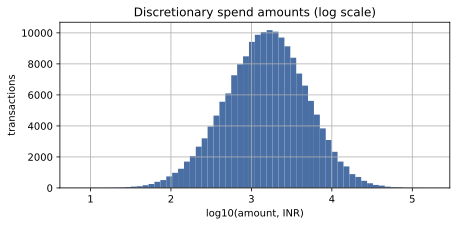

,median_inr
category,
travel,"1,902.21"
utilities,"1,681.93"
shopping,"1,591.66"
groceries,"1,468.71"
transport,"1,464.43"
dining,"1,427.43"
entertainment,"1,296.14"


In [4]:
disc = txns[txns.event_type == "DISCRETIONARY"]
fig, ax = plt.subplots()
ax.hist(np.log10(disc["amount_inr"]), bins=60, color="#4a6fa5")
ax.set_xlabel("log10(amount, INR)")
ax.set_ylabel("transactions")
ax.set_title("Discretionary spend amounts (log scale)")
plt.show()
disc.groupby("category")["amount_inr"].median().sort_values(ascending=False).to_frame("median_inr")

## 3. Inter-arrival times

Gap between consecutive transactions of the same customer. Most gaps are hours to a day; the
short tail (minutes) is what `transfer_velocity_10m` measures. Students and business owners
transact most often; retirees least.

In [5]:
ordered = txns.sort_values(["customer_id", "occurred_at"])
gaps_h = ordered.groupby("customer_id")["occurred_at"].diff().dt.total_seconds().div(3600).dropna()
ordered = ordered.loc[gaps_h.index].assign(gap_h=gaps_h)
summary = ordered.groupby("persona")["gap_h"].quantile([0.1, 0.5, 0.9]).unstack()
summary.columns = ["p10_hours", "median_hours", "p90_hours"]
print(f"share of gaps under 10 minutes: {(gaps_h < 1 / 6).mean():.2%}")
summary

share of gaps under 10 minutes: 1.78%


,p10_hours,median_hours,p90_hours
persona,,,
business_owner,0.90,12.65,41.30
freelancer,1.12,18.17,48.54
retiree,2.47,26.97,96.87
salaried_professional,1.02,17.47,47.04
student,1.20,19.80,52.56


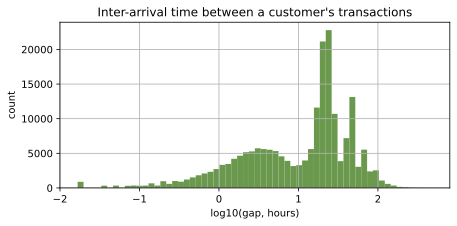

In [6]:
fig, ax = plt.subplots()
ax.hist(np.log10(gaps_h.clip(lower=1 / 60)), bins=60, color="#6a994e")
ax.set_xlabel("log10(gap, hours)")
ax.set_ylabel("count")
ax.set_title("Inter-arrival time between a customer's transactions")
plt.show()

## 4. Calendar effects the generator must show

Electricity bills should peak in the Indian summer (May), discretionary activity should rise in
the festive season (Oct-Nov), and salaries should land on the last business day.

In [7]:
txns["month"] = txns["occurred_at"].dt.tz_convert("Asia/Kolkata").dt.month
electricity = (
    txns[txns.merchant == "State Power Distribution"].groupby("month")["amount_inr"].mean()
)
festive = txns[txns.event_type == "DISCRETIONARY"].groupby("month").size()
calendar_view = pd.DataFrame({"mean_electricity_inr": electricity, "discretionary_txns": festive})
assert calendar_view["mean_electricity_inr"].idxmax() == 5, "summer spike missing"
assert festive[11] > festive[9], "festive uplift missing"
calendar_view

,mean_electricity_inr,discretionary_txns
month,,
1,"2,938.82",13959
2,"2,641.41",13989
3,"2,967.58",14048
4,"3,601.11",13879
5,"4,264.75",13831
6,"3,889.85",13877
7,"2,939.84",13513
8,"2,553.85",13418
9,"2,569.64",13449


In [8]:
salary_days = txns[txns.event_type == "SALARY"]["occurred_at"].dt.tz_convert("Asia/Kolkata")
print(
    "salary credits by weekday (0=Mon):",
    salary_days.dt.weekday.value_counts().sort_index().to_dict(),
)
print("all salary credits fall on business days:", bool((salary_days.dt.weekday < 5).all()))

salary credits by weekday (0=Mon): {0: 410, 1: 200, 2: 405, 3: 200, 4: 1222}
all salary credits fall on business days: True


## 5. Churn

A customer churns when they go permanently silent (`churned_on`). Churn is persona-dependent
(students highest). Activity in the 30 days *before* churn is a useful signal - but it must be
measured strictly before the churn is observed, which is the leakage question in section 7.

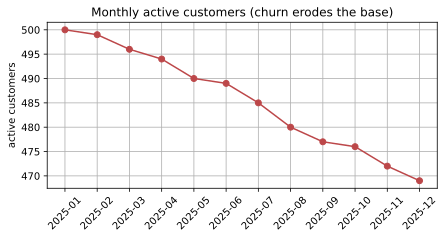

,churned_customers,churn_rate_12m
persona,,
business_owner,6,0.07
freelancer,6,0.09
retiree,2,0.03
salaried_professional,9,0.04
student,11,0.15


In [9]:
churn = (
    customers.assign(churned=customers["churned_on"].notna())
    .groupby("persona")["churned"]
    .agg(["sum", "mean"])
)
churn.columns = ["churned_customers", "churn_rate_12m"]
months = pd.period_range("2025-01", periods=12, freq="M")
local_month = (
    txns["occurred_at"].dt.tz_convert("Asia/Kolkata").dt.tz_localize(None).dt.to_period("M")
)
active = [txns[local_month == m]["customer_id"].nunique() for m in months]
fig, ax = plt.subplots()
ax.plot([str(m) for m in months], active, marker="o", color="#bc4749")
ax.set_ylabel("active customers")
ax.set_title("Monthly active customers (churn erodes the base)")
ax.tick_params(axis="x", rotation=45)
plt.show()
churn

## 6. Feature contract draft (`pbip_ml.features.contract`)

The draft defines behavioural features as Pydantic models (strict, frozen, `extra="forbid"`),
with the two required by the backlog - `avg_amount_30d` and `transfer_velocity_10m` - plus context
features mapped to the fraud scenarios in the blueprint (F1, F2, F5, F6, F8).

In [10]:
pd.DataFrame([d.model_dump() for d in FEATURE_CATALOGUE]).set_index("name")[
    ["dtype", "window", "unit", "description"]
]

,dtype,window,unit,description
name,,,,
avg_amount_30d,int,30d,paise,Mean debit amount; baseline for amount-spike r...
max_amount_30d,int,30d,paise,Largest debit; caps what 'unusually large' mea...
debit_count_30d,int,30d,count,Number of debits; activity level and dormancy ...
debit_total_30d,int,30d,paise,Total outflow; with credit_total_30d gives pas...
credit_total_30d,int,30d,paise,"Total inflow (salary, receipts)."
transfer_velocity_10m,int,10m,count,Debits in the last 10 minutes; velocity-burst ...
transfer_velocity_24h,int,24h,count,Debits in the last 24 hours; slower velocity c...
distinct_merchants_30d,int,30d,count,Merchant diversity; new-counterparty context (...
night_debit_ratio_30d,float,30d,ratio,Share of debits between 00:00 and 05:59 IST; u...


In [11]:
AS_OF = datetime(2025, 10, 1, tzinfo=UTC)
events_by_customer = {cid: [] for cid in customers["id"]}
for t in dataset.transactions:
    events_by_customer[t.customer_id].append(
        TransactionEvent(
            customer_id=t.customer_id,
            occurred_at=t.occurred_at,
            direction=t.direction,
            amount_minor=t.amount_minor,
            merchant=t.merchant,
        )
    )
features = pd.DataFrame(
    [
        compute_customer_features(cid, events, AS_OF).model_dump()
        for cid, events in events_by_customer.items()
    ]
)
features[
    [
        "avg_amount_30d",
        "debit_count_30d",
        "transfer_velocity_10m",
        "distinct_merchants_30d",
        "night_debit_ratio_30d",
        "days_since_last_txn",
    ]
].describe().T[["mean", "50%", "max"]]

,mean,50%,max
avg_amount_30d,"333,355.18","268,609.00","1,984,212.00"
debit_count_30d,29.17,30.00,61.00
transfer_velocity_10m,0.00,0.00,0.00
distinct_merchants_30d,18.02,19.00,28.00
night_debit_ratio_30d,0.00,0.00,0.00
days_since_last_txn,7.30,0.58,269.25


## 7. Target leakage validation

Label for this illustration: *churns within 90 days after `AS_OF`*. Rules enforced and checked:

1. **Point in time:** features use only events strictly before `AS_OF`; the label window starts at `AS_OF`.
2. **Invariance test:** recomputing features from history truncated at `AS_OF` gives identical vectors.
3. **No label columns:** the input schema rejects any label-like field.
4. **Counter-example:** a naive implementation that looks at *all* events leaks - its
   "recency" feature separates churners almost perfectly, which is exactly the bias the contract prevents.

In [12]:
label_end = AS_OF + pd.Timedelta(days=90)
churned_on = pd.to_datetime(customers.set_index("id")["churned_on"])
start_day, end_day = pd.Timestamp(AS_OF.date()), pd.Timestamp(label_end.date())
label = churned_on.between(start_day, end_day).rename("churn_next_90d")
already_churned = churned_on.lt(start_day)

# (2) invariance: truncating history at AS_OF changes nothing
truncated = pd.DataFrame(
    [
        compute_customer_features(
            cid, [e for e in events if e.occurred_at < AS_OF], AS_OF
        ).model_dump()
        for cid, events in events_by_customer.items()
    ]
)
assert truncated.equals(features), "features changed when future events were removed: LEAKAGE"

# (3) schema rejects label columns
try:
    TransactionEvent.model_validate(
        {**events_by_customer[customers["id"][0]][0].model_dump(), "churned": True}
    )
    raise AssertionError("label column accepted")
except ValueError:
    pass
print("point-in-time invariance: OK; label fields rejected: OK")

point-in-time invariance: OK; label fields rejected: OK


In [13]:
eval_set = features.set_index("customer_id").join(label).loc[~already_churned.values]
naive_last_seen = txns.groupby("customer_id")["occurred_at"].max()
naive_recency = (pd.Timestamp(label_end) - naive_last_seen).dt.days  # uses the FUTURE
eval_set = eval_set.join(naive_recency.rename("naive_recency_days"))


def separation(col):  # gap in medians between churners and non-churners, in pooled std units
    a, b = eval_set[eval_set.churn_next_90d][col], eval_set[~eval_set.churn_next_90d][col]
    return (a.median() - b.median()) / eval_set[col].std()


pd.Series(
    {
        "contract days_since_last_txn (as of AS_OF)": separation("days_since_last_txn"),
        "naive recency using future events (LEAKS)": separation("naive_recency_days"),
        "churners in label window": int(eval_set.churn_next_90d.sum()),
    }
).to_frame("value")

,value
contract days_since_last_txn (as of AS_OF),0.28
naive recency using future events (LEAKS),5.60
churners in label window,10.00


## Findings

* **Amounts:** heavy right tail; per-customer baselines (`avg_amount_30d`, `max_amount_30d`) are needed
  rather than global thresholds - a ₹5,000 spend is routine for one persona and an outlier for another.
* **Inter-arrival:** the median gap is hours, sub-10-minute gaps are rare, so `transfer_velocity_10m`
  is a meaningful burst signal (F2) with a low natural base rate.
* **Calendar:** the summer electricity spike, festive uplift and last-business-day salaries are present,
  so forecasting/seasonality work in later sprints has signal to find.
* **Generator gap found:** v1 produces no activity between 00:00 and 05:59 IST, so
  `night_debit_ratio_30d` is constant (0) on this data - the feature is kept in the contract because
  account-takeover scenarios (F3) need it, and data-gen v2 must add realistic night activity.
* **Churn:** persona-dependent; recency is informative *only when computed point-in-time*. The naive
  "recency" that peeks past `AS_OF` looks spectacular - that is leakage, and the contract makes it
  impossible by construction (strict `< as_of` filter, label-free inputs, invariance test).

**Limitations:** hand-specified distributions; no fraud labels yet (data-gen v2); no device/login events
(the `SECURITY_EVENTS` source is reserved); results describe the generator, not real customers.